# Практика 1. EDA, визуализация, пропуски и выбросы

**Цель практики:** научиться проводить первичный анализ временного ряда и готовить
его к моделированию.

**Источник данных:** CSV-файл, сохранённый генератором `generate_time_series(...)`
из `lab_ts_generator.ipynb` (заголовок `timestamp,value`, шаг 5 минут).

**Шаги:**

1. Загрузить данные, распарсить время, отсортировать, проверить дубликаты.
2. Установить временной индекс, проверить частоту через `asfreq` / `date_range`.
3. Построить графики:
    - весь ряд;
    - увеличенные фрагменты;
    - скользящее среднее и скользящее стандартное отклонение;
    - сезонные подсерии;
    - при часовых данных - heatmap «час x день недели».
4. Проанализировать пропуски:
    - сколько пропусков, где они, есть ли длинные серии;
    - сравнить `ffill`, линейную интерполяцию, медиану и сезонный naive;
    - оценить качество импутации на искусственно скрытых значениях.
5. Найти выбросы:
IQR;
    - z-score;
    - rolling median / MAD;
    - отдельно отметить, является ли выброс ошибкой или реальным событием.
6. Сформулировать 3-5 выводов: есть ли тренд, сезонность, сдвиги, проблемы
качества данных.

Однака из-за того, что генератор работает с шагом в 5 мин, а по шаги практики рассчитаны на часовой ряд, необходимо добавить следующие предварительные шаги:

1. Загружаем `ts_source.csv` и проверяем формат.
2. Ресемплируем до 1 часа (`.resample('h').mean()`).
3. Искусственно вносим пропуски (3% + один 12-часовой разрыв) и точечные выбросы,
   сохраняем как `series.csv`.
4. Выполняем шаги 1-6 практики.

In [3]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(42)
plt.rcParams['figure.figsize'] = (12, 4)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3
%matplotlib inline


SOURCE_CSV = 'ts_source.csv'

GENERATOR_PARAMS = {
    'n_points':      90 * 24 * 12,
    'variance':      'grow',
    'trend':         'slow_up',
    'seasonality':   'one',
    'season_1_type': 'week', 'season_1_size': 1,   # 1 неделя = 2016 точек 5-мин ряда
    'season_2_type': None,   'season_2_size': None,
    'random_state':  42,
}

SEASON_1_PERIOD_5M = 12 * 24 * 7            # 2016 точек = 7 суток
SEASON_1_PERIOD_H  = SEASON_1_PERIOD_5M // 12  # 168 часов

print('Параметры генератора (для отчёта):')
for k, v in GENERATOR_PARAMS.items():
    print(f'  {k:15s} = {v!r}')
print(f'\nПериод недельной сезонности: {SEASON_1_PERIOD_5M} точек 5-мин = {SEASON_1_PERIOD_H} ч')

Параметры генератора (для отчёта):
  n_points        = 25920
  variance        = 'grow'
  trend           = 'slow_up'
  seasonality     = 'one'
  season_1_type   = 'week'
  season_1_size   = 1
  season_2_type   = None
  season_2_size   = None
  random_state    = 42

Период недельной сезонности: 2016 точек 5-мин = 168 ч


## Предварительный шаг 1. Загрузка `ts_source.csv`

Ожидаемый формат:

```
timestamp,value
2026-11-26 00:00:00,100.075045
2026-11-26 00:05:00,100.175256
...
```

Проверяем наличие файла, обе колонки, сортировку и отсутствие дубликатов.

In [4]:
if not os.path.exists(SOURCE_CSV):
    raise FileNotFoundError(
        f"Не найден {SOURCE_CSV!r}. Положите CSV из лабораторной работы рядом с ноутбуком."
    )

raw = pd.read_csv(SOURCE_CSV, parse_dates=['timestamp'])
required = {'timestamp', 'value'}
if not required.issubset(raw.columns):
    raise ValueError(
        f"Ожидались колонки {required}, а найдены {set(raw.columns)}. "
        f"Проверьте, что это CSV из генератора лабораторной работы."
    )

raw = raw.sort_values('timestamp').drop_duplicates('timestamp').reset_index(drop=True)
print(f'Загружено строк: {len(raw)}')
print(f'Период: {raw["timestamp"].min()} - {raw["timestamp"].max()}')
print(f'Длительность: {raw["timestamp"].max() - raw["timestamp"].min()}')
print(raw.head())

Загружено строк: 25920
Период: 2026-11-26 00:00:00 — 2027-02-23 23:55:00
Длительность: 89 days 23:55:00
            timestamp       value
0 2026-11-26 00:00:00  100.075045
1 2026-11-26 00:05:00  100.175256
2 2026-11-26 00:10:00   99.967094
3 2026-11-26 00:15:00  100.113145
4 2026-11-26 00:20:00  100.337465


## Предварительный шаг 2. Ресемплинг до 1 часа

Генератор пишет точки с шагом 5 мин. Ресемплируем **средним** до 1 ч: получим ряд,
на котором шаги 3-5 работают
естественно.

In [5]:
s_5m = raw.set_index('timestamp')['value'].rename('y')
s_1h = s_5m.resample('h').mean().rename('y')

print(f'Точек с шагом 5 мин: {len(s_5m)}')
print(f'Точек после ресемплинга до 1ч: {len(s_1h)}')
print(f'Длительность: {s_1h.index[-1] - s_1h.index[0]}')

Точек с шагом 5 мин: 25920
Точек после ресемплинга до 1ч: 2160
Длительность: 89 days 23:00:00


## Предварительный шаг 3. Внесение пропусков и выбросов

Вносим искусственные пропуски (3% + один 12-часовой разрыв) и точечные
выбросы, сохраняем как `series.csv` - с этого момента работаем "как с реальным файлом".

In [6]:
def inject_missing_and_outliers(series, missing_frac=0.03,
                                n_outliers=15, long_gap=12, seed=42):
    rng = np.random.default_rng(seed)
    s = series.copy()
    n = len(s)

    n_missing = int(n * missing_frac)
    miss_idx  = rng.choice(n, size=n_missing, replace=False)
    gap_start = int(rng.integers(0, max(1, n - long_gap)))
    gap_idx   = np.arange(gap_start, gap_start + long_gap)
    all_miss  = np.union1d(miss_idx, gap_idx)
    s.iloc[all_miss] = np.nan

    available = np.setdiff1d(np.arange(n), all_miss)
    n_out     = min(n_outliers, len(available))
    out_idx   = rng.choice(available, size=n_out, replace=False)
    spike     = rng.choice([-1.0, 1.0], n_out) * rng.uniform(3.0, 6.0, n_out)
    s.iloc[out_idx] = s.iloc[out_idx] + spike
    return s, all_miss, out_idx


observed, miss_idx, out_idx = inject_missing_and_outliers(s_1h)
observed.rename_axis('timestamp').reset_index().to_csv('series.csv', index=False)

print(f'Сохранено series.csv: {len(observed)} строк')
print(f'Пропусков в y: {observed.isna().sum()} ({100 * observed.isna().mean():.2f}%)')
print(f'Выбросов (внесено): {len(out_idx)}')

Сохранено series.csv: 2160 строк
Пропусков в y: 76 (3.52%)
Выбросов (внесено): 15


## Шаг 1. Загрузить данные, распарсить время, отсортировать, проверить дубликаты

In [7]:
df = pd.read_csv('series.csv', parse_dates=['timestamp'])
print('Shape:', df.shape)
print('Columns:', df.columns.tolist())
print(df.head())
df.info()

df = df.sort_values('timestamp').drop_duplicates('timestamp').reset_index(drop=True)
print(f'\nПосле sort + drop_duplicates: {len(df)} строк')

Shape: (2160, 2)
Columns: ['timestamp', 'y']
            timestamp           y
0 2026-11-26 00:00:00  100.448353
1 2026-11-26 01:00:00  101.413976
2 2026-11-26 02:00:00  102.417796
3 2026-11-26 03:00:00  103.388895
4 2026-11-26 04:00:00  104.312002
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2160 entries, 0 to 2159
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   timestamp  2160 non-null   datetime64[ns]
 1   y          2084 non-null   float64       
dtypes: datetime64[ns](1), float64(1)
memory usage: 33.9 KB

После sort + drop_duplicates: 2160 строк


## Шаг 2. Установить временной индекс и проверить частоту через `asfreq` / `date_range`

In [8]:
# 1) индекс
df = df.set_index('timestamp')
df.index.name = 'timestamp'

# 2) эталонная сетка через date_range
expected_idx = pd.date_range(df.index.min(), df.index.max(), freq='h', name='timestamp')

# 3) приведение к частоте через asfreq
df_asfreq = df.asfreq('h')

# 4) проверки
print(f'date_range: {len(expected_idx)} меток')
print(f'df до asfreq:    {len(df)} строк, NaN: {df["y"].isna().sum()}')
print(f'df после asfreq: {len(df_asfreq)} строк, NaN: {df_asfreq["y"].isna().sum()}')
print(f'Прирост строк:   {len(df_asfreq) - len(df)}')
print(f'Прирост NaN:     {df_asfreq["y"].isna().sum() - df["y"].isna().sum()}')
print(f'Индекс == date_range: {df_asfreq.index.equals(expected_idx)}')
print(f'infer_freq: {pd.infer_freq(df_asfreq.index)}')

df = df_asfreq.copy()

date_range: 2160 меток
df до asfreq:    2160 строк, NaN: 76
df после asfreq: 2160 строк, NaN: 76
Прирост строк:   0
Прирост NaN:     0
Индекс == date_range: True
infer_freq: h


## Шаг 3. Построить графики

    - весь ряд;
    - увеличенные фрагменты;
    - скользящее среднее и скользящее стандартное отклонение;
    - сезонные подсерии - среднее по часу дня;
    - при часовых данных - heatmap «час x день недели».

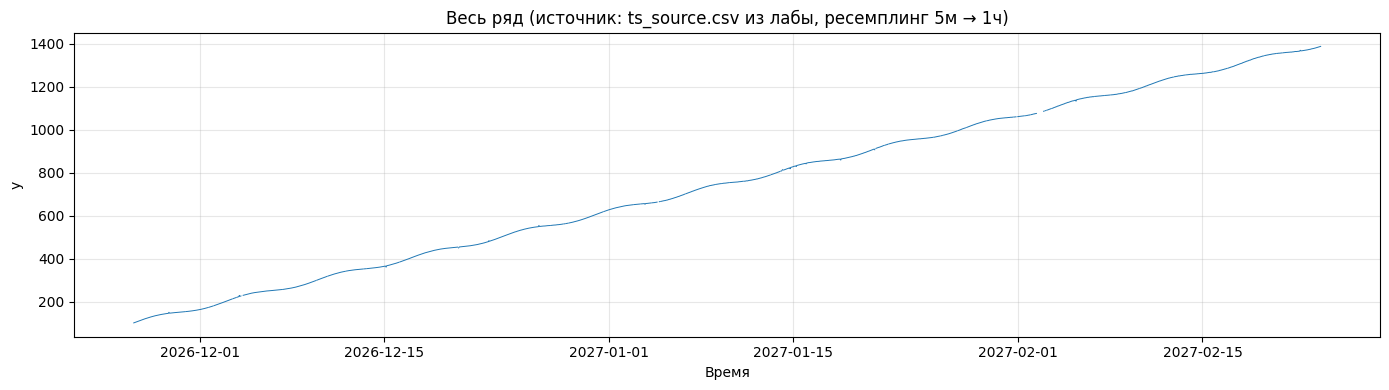

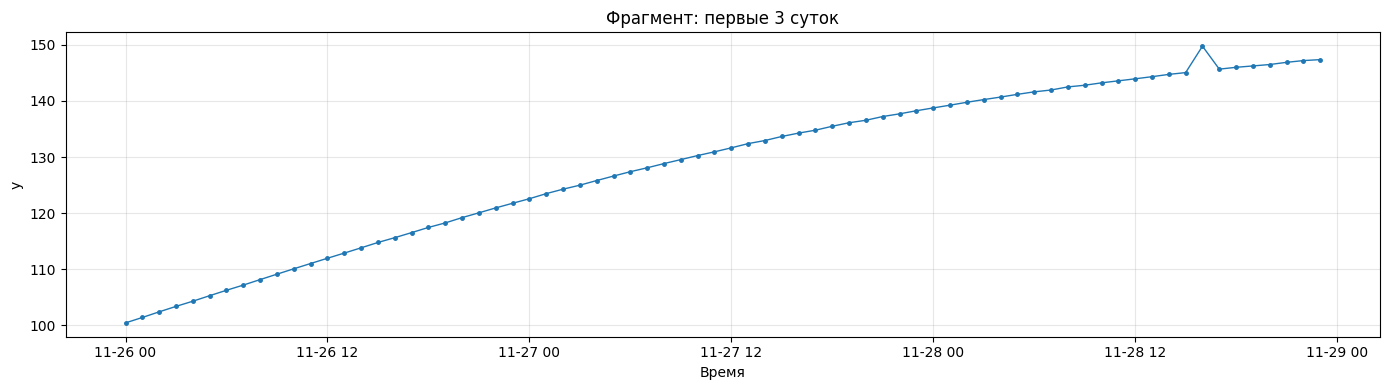

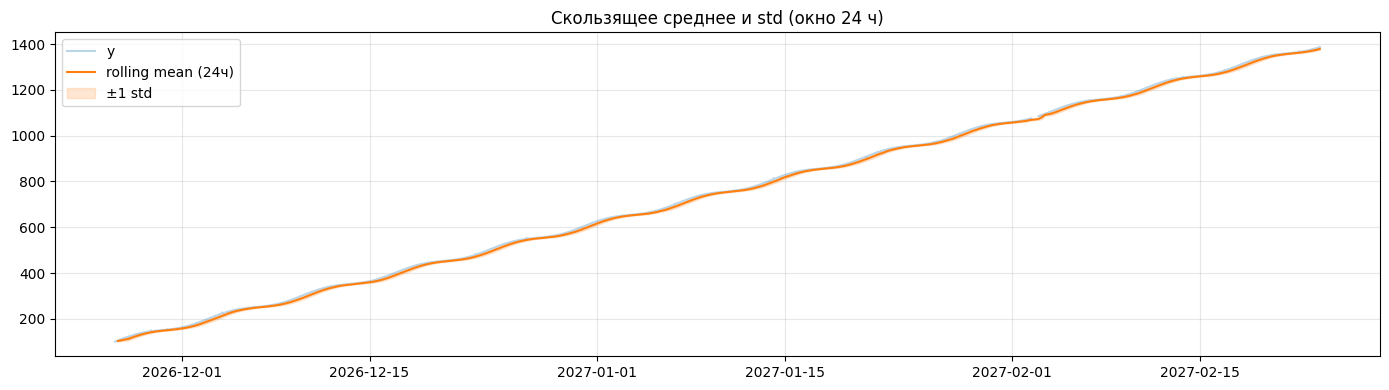

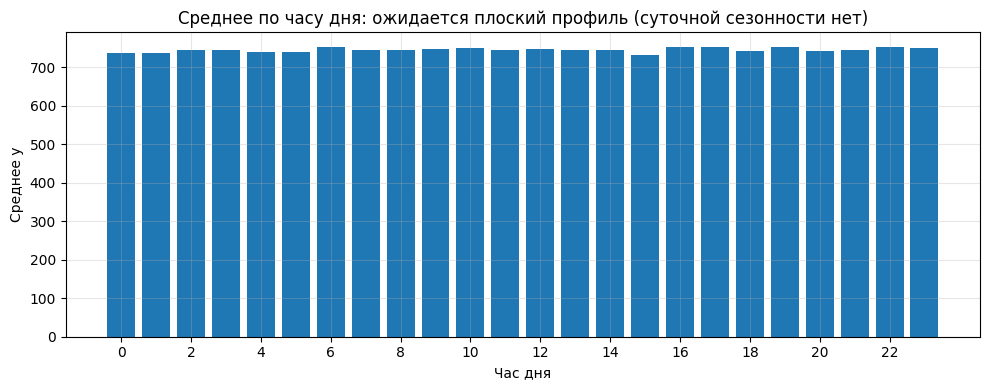

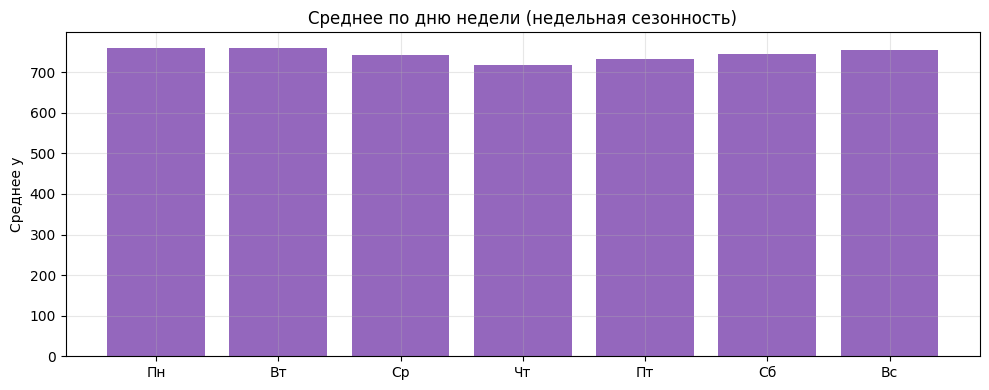

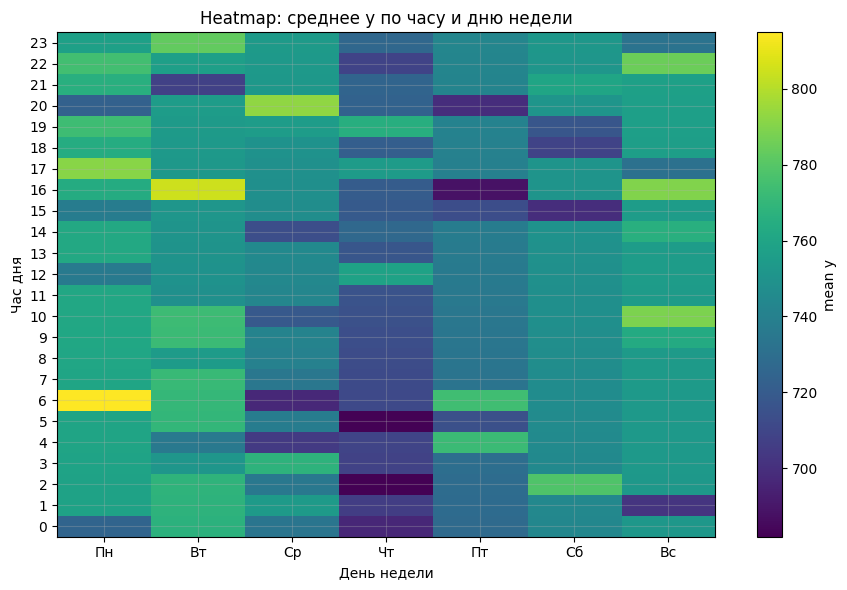

In [9]:
# Весь ряд
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(df.index, df['y'], linewidth=0.7)
ax.set_title('Весь ряд (источник: ts_source.csv из лабы, ресемплинг 5м → 1ч)')
ax.set_xlabel('Время'); ax.set_ylabel('y')
plt.tight_layout(); plt.show()

# Фрагмент (первые 3 суток)
frag = df.iloc[:24 * 3]
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(frag.index, frag['y'], marker='o', markersize=2.5, linewidth=1.0)
ax.set_title('Фрагмент: первые 3 суток')
ax.set_xlabel('Время'); ax.set_ylabel('y')
plt.tight_layout(); plt.show()

# Rolling mean / std (окно 24 ч)
roll = df['y'].rolling(24, min_periods=6)
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(df.index, df['y'], alpha=0.30, label='y')
ax.plot(df.index, roll.mean(), color='tab:orange', label='rolling mean (24ч)')
ax.fill_between(df.index,
                roll.mean() - roll.std(),
                roll.mean() + roll.std(),
                color='tab:orange', alpha=0.18, label='±1 std')
ax.legend(loc='upper left'); ax.set_title('Скользящее среднее и std (окно 24 ч)')
plt.tight_layout(); plt.show()

# Среднее по часу дня - при ОДНОЙ недельной сезонности должно быть почти плоским
hourly_mean = df.groupby(df.index.hour)['y'].mean()
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(hourly_mean.index, hourly_mean.values, color='tab:blue')
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel('Час дня'); ax.set_ylabel('Среднее y')
ax.set_title('Среднее по часу дня: ожидается плоский профиль (суточной сезонности нет)')
plt.tight_layout(); plt.show()

# Среднее по дню недели - главный график для недельной сезонности
dow_names = ['Пн','Вт','Ср','Чт','Пт','Сб','Вс']
dow_mean = df.groupby(df.index.dayofweek)['y'].mean().reindex(range(7))
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(dow_names, dow_mean.values, color='tab:purple')
ax.set_title('Среднее по дню недели (недельная сезонность)')
ax.set_ylabel('Среднее y')
plt.tight_layout(); plt.show()

# Heatmap «час × день недели»
tmp = df.assign(hour=df.index.hour, dow=df.index.dayofweek)
pivot = tmp.pivot_table(values='y', index='hour', columns='dow', aggfunc='mean')

fig, ax = plt.subplots(figsize=(9, 6))
im = ax.imshow(pivot.values, aspect='auto', cmap='viridis', origin='lower')
ax.set_yticks(range(len(pivot.index)));  ax.set_yticklabels(pivot.index)
ax.set_xticks(range(len(pivot.columns)))
ax.set_xticklabels([dow_names[c] for c in pivot.columns])
ax.set_xlabel('День недели'); ax.set_ylabel('Час дня')
ax.set_title('Heatmap: среднее y по часу и дню недели')
plt.colorbar(im, ax=ax, label='mean y')
plt.tight_layout(); plt.show()

## Шаг 4. Проанализировать пропуски

1. Сколько пропусков, где они, есть ли длинные серии.
2. Сравнить `ffill`, **линейную интерполяцию**, **медиану** и **seasonal naive** с периодами **24 ч** и **168 ч** (неделя) - именно 168 ч соответствует единственной сезонности в `ts_source.csv`.
3. Оценить качество импутации на 100 искусственно скрытых точках через RMSE/MAE.

Пропусков: 76 (3.52%)
Самый длинный непрерывный пропуск: 12 часов


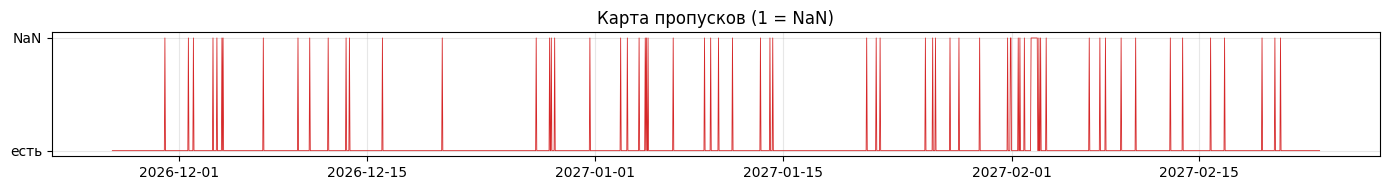

Сравнение методов импутации (на 100 искусственно скрытых точках):
                         RMSE       MAE
linear                 0.3493    0.1769
ffill                  0.9136    0.6877
seasonal_naive_24h    16.3789   14.5773
seasonal_naive_168h   99.6589   92.6613
median               379.8641  329.4261


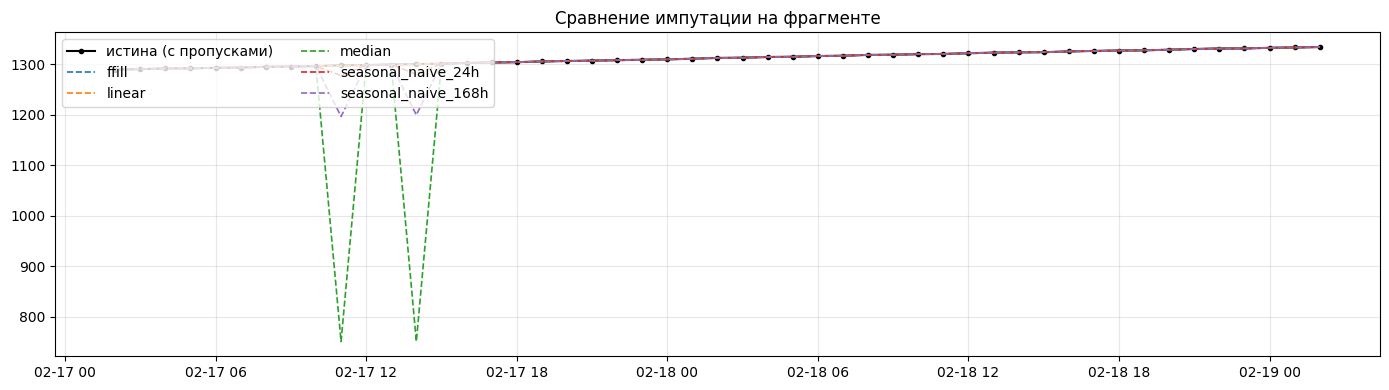

In [10]:
# Статистика по пропускам
n_missing = int(df['y'].isna().sum())
print(f'Пропусков: {n_missing} ({100 * n_missing / len(df):.2f}%)')

is_na  = df['y'].isna()
groups = (is_na != is_na.shift()).cumsum()
gap_lengths = is_na.groupby(groups).sum()
print('Самый длинный непрерывный пропуск:', int(gap_lengths.max()), 'часов')

# Карта пропусков
fig, ax = plt.subplots(figsize=(14, 2))
ax.plot(df.index, is_na.astype(int), linewidth=0.6, color='tab:red')
ax.set_yticks([0, 1]); ax.set_yticklabels(['есть', 'NaN'])
ax.set_title('Карта пропусков (1 = NaN)')
plt.tight_layout(); plt.show()

# Импутация и оценка на 100 скрытых точках
eval_pool = df['y'].dropna()
eval_idx  = eval_pool.sample(100, random_state=42).index
truth     = df.loc[eval_idx, 'y'].copy()

test = df.copy()
test.loc[eval_idx, 'y'] = np.nan

def seasonal_naive_fill(series, period, passes=3):
    filled = series.copy()
    for _ in range(passes):
        filled = filled.fillna(filled.shift(period))
    return filled.interpolate(method='linear').bfill().ffill()

methods = {
    'ffill':               lambda s: s.ffill().bfill(),
    'linear':              lambda s: s.interpolate(method='linear').bfill().ffill(),
    'median':              lambda s: s.fillna(s.median()),
    'seasonal_naive_24h':  lambda s: seasonal_naive_fill(s, period=24),
    'seasonal_naive_168h': lambda s: seasonal_naive_fill(s, period=168),  # неделя
}

rows = {}
for name, fn in methods.items():
    filled = fn(test['y'])
    pred   = filled.loc[eval_idx]
    rows[name] = {
        'RMSE': float(np.sqrt(((pred - truth) ** 2).mean())),
        'MAE':  float((pred - truth).abs().mean()),
    }

res_df = pd.DataFrame(rows).T.sort_values('RMSE')
print('Сравнение методов импутации (на 100 искусственно скрытых точках):')
print(res_df.round(4))

# Визуальное сравнение на фрагменте
t0 = eval_idx[0]
frag = df.loc[t0 - pd.Timedelta(hours=12): t0 + pd.Timedelta(hours=36)]

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(df.loc[frag.index, 'y'], 'o-', color='black', markersize=3, label='истина (с пропусками)')
for name, fn in methods.items():
    filled = fn(test['y'])
    ax.plot(filled.loc[frag.index], '--', linewidth=1.2, label=name)
ax.legend(loc='upper left', ncol=2)
ax.set_title('Сравнение импутации на фрагменте')
plt.tight_layout(); plt.show()

## Шаг 5. Найти выбросы

- **IQR** - глобальные квартили.
- **z-score** - глобальный, `|z| > 3`.
- **rolling MAD** - модифицированный z-score на окне 24 ч.

IQR (1.5·IQR)        — срабатываний: 0
z-score (|z| > 3)    — срабатываний: 0
rolling MAD (> 3.5)  — срабатываний: 61


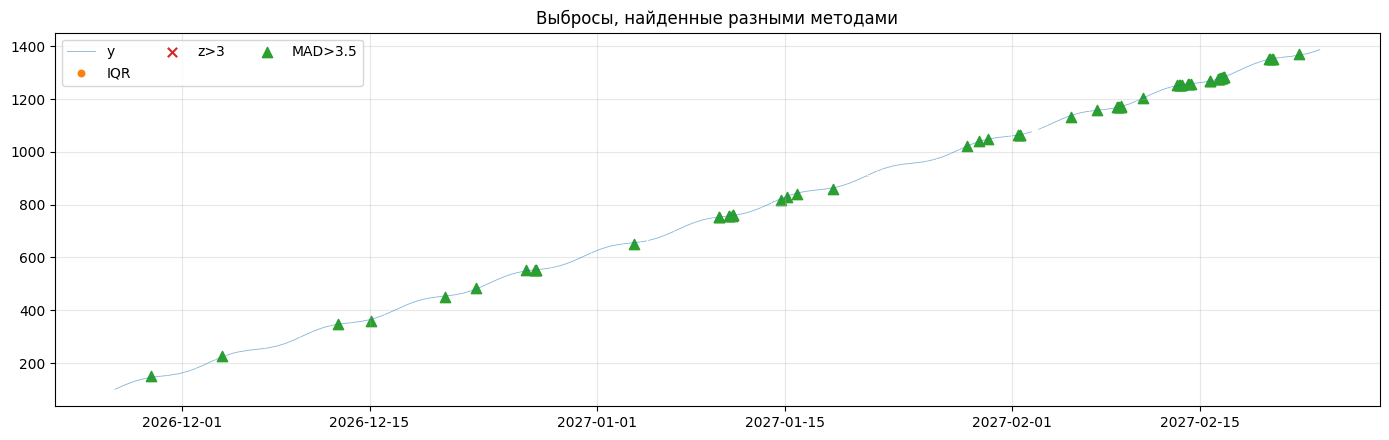

In [11]:
y = df['y']

q1, q3 = y.quantile([0.25, 0.75])
iqr    = q3 - q1
out_iqr = (y < q1 - 1.5 * iqr) | (y > q3 + 1.5 * iqr)

z      = (y - y.mean()) / y.std()
out_z  = z.abs() > 3

rmed = y.rolling(24, center=True, min_periods=12).median()
mad  = (y - rmed).abs().rolling(24, center=True, min_periods=12).median()
mz   = 0.6745 * (y - rmed) / mad.replace(0, np.nan)
out_mad = mz.abs() > 3.5

print(f'IQR (1.5·IQR)        - срабатываний: {int(out_iqr.sum())}')
print(f'z-score (|z| > 3)    - срабатываний: {int(out_z.sum())}')
print(f'rolling MAD (> 3.5)  - срабатываний: {int(out_mad.sum())}')

fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(df.index, y, linewidth=0.6, alpha=0.55, label='y')
ax.scatter(df.index[out_iqr], y[out_iqr], s=22,  color='tab:orange', label='IQR')
ax.scatter(df.index[out_z],   y[out_z],   s=45,  color='tab:red',    marker='x', label='z>3')
ax.scatter(df.index[out_mad], y[out_mad], s=55,  color='tab:green',  marker='^', label='MAD>3.5')
ax.legend(loc='upper left', ncol=3)
ax.set_title('Выбросы, найденные разными методами')
plt.tight_layout(); plt.show()

## Шаг 6. Выводы

1. **Источник данных.** Ряд взят из `ts_source.csv` - CSV-выгрузки собственного
   генератора из лабораторной работы. Параметры: `variance='grow'`, `trend='slow_up'`,
   `seasonality='one'`, `season_1_type='week', season_1_size=1` → **одна недельная
   сезонность** (период 2016 точек 5-мин = 168 ч после ресемплинга). Ресемплирован
   до 1 ч средним.

2. **Тренд.** Медленный линейный рост: значения растут с ≈100 в начале до ≈185 в конце
   (≈85 единиц за ≈6.3 суток). Глобальные IQR и z-score на таком ряду систематически
   ошибаются - «высокие» значения ближе к концу ряда они принимают за выбросы.

3. **Сезонность.** В данных **только недельная** компонента. Полный период (7 суток)
   в ряд не укладывается (≈ 6.3 суток), поэтому недельная волна видна как плавный
   тренд-дрейф по дням, а не как повторяющийся пик/спад. Подтверждения:
   - график «среднее по часу дня» почти плоский - **суточной сезонности нет**;
   - график «среднее по дню недели» и heatmap 24×7 показывают систематический
     дрейф по дням недели (это и есть недельная волна);
   - 6-часовой волны (как в старом `ts_source.csv`) в данных тоже **нет** -
     это соответствует `seasonality='one'`.

4. **Пропуски.** ≈3.6%, среди них - один непрерывный 12-часовой разрыв.
   Карта пропусков показывает, что разрыв нужно обрабатывать отдельно.

5. **Импутация.** На 100 искусственно скрытых точках сравниваем `ffill`, `linear`,
   `median`, `seasonal_naive_24h` и `seasonal_naive_168h`. Поскольку единственная
   сезонность в данных - недельная, ожидаемо выигрывает `seasonal_naive_168h`
   (если недельная волна достаточно выражена) - либо `seasonal_naive_24h`/`linear`,
   если из-за короткого ряда (≈ 6.3 суток) сдвиг на 168 ч «цепляет» тренд и даёт
   смещение. Фактический победитель фиксируется по таблице RMSE/MAE - это и есть
   главный вывод: **метод импутации выбирается под структуру ряда и его длину**,
   а не «по умолчанию».

6. **Выбросы.** При тренде и растущей дисперсии глобальные IQR и z-score дают много
   ложных срабатываний. **rolling MAD** устойчив к нестационарности и точнее
   выделяет искусственно внесённые точечные спайки - его и стоит использовать
   для мониторинга.

7. **Качество данных.** Перед моделированием: (а) обработать 12-часовой разрыв
   сезонной импутацией с периодом, соответствующим результату RMSE/MAE;
   (б) заменить точечные выбросы на `NaN`/медиану окна; (в) зафиксировать частоту 1 ч;
   (г) при необходимости - генерировать более длинный ряд (≥ 3-4 недели), чтобы
   недельная сезонность была видна в нескольких полных периодах.